In [1]:
from sentence_transformers import SentenceTransformer

bert_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding dimensions:", bert_model.get_embedding_dimension())
print("Maximum sequence length:", bert_model.max_seq_length)

W1115 10:34:24.863000 7713 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding dimensions: 384
Maximum sequence length: 256


# Load all data

In [2]:

from pathlib import Path
import pandas as pd

# Find all book and movie files
book_files = sorted(Path("../book_data").glob("book*_dialogue.csv"))
movie_files = sorted(Path("../movie_data").glob("hp*.csv"))

print("Book files:", len(book_files))
print("Movie files:", len(movie_files))


def load_files(files, version):

    frames = []

    for file in files:
        temp = pd.read_csv(file)

        temp["version"] = version
        temp["source_file"] = file.stem

        frames.append(temp)

    return pd.concat(frames, ignore_index=True)


books = load_files(book_files, "book")
movies = load_files(movie_files, "movie")

# Combine all dialogue
df = pd.concat([books, movies], ignore_index=True)

print(df.groupby("version").size())

Book files: 7
Movie files: 8
version
book     35550
movie     7445
dtype: int64


### Dialog data. Group by character and count words in dialog for later use

In [3]:
import pandas as pd
import numpy as np

df["version"] = (
    df["version"]
    .str.lower()
    .replace({"film": "movie"})
)

df["dialog"] = df["dialog"].fillna("").astype(str)

# Remove empty dialogue
df = df[df["dialog"].str.strip() != ""].copy()

# Count words per dialogue
df["word_count"] = df["dialog"].str.split().str.len()

In [4]:
character_dialogues = (
    df.groupby(["version", "character"], sort=False)["dialog"]
    .apply(list)
    .to_dict()
)

print("Number of character/version combinations:", len(character_dialogues))

Number of character/version combinations: 284


In [10]:
# Separate book and movie dialogue

book_character_dialogues = {
    character: dialogues
    for (version, character), dialogues in character_dialogues.items()
    if version == "book"
}

movie_character_dialogues = {
    character: dialogues
    for (version, character), dialogues in character_dialogues.items()
    if version == "movie"
}

print("Book characters:", len(book_character_dialogues))
print("Movie characters:", len(movie_character_dialogues))

Book characters: 115
Movie characters: 169


Split long occurrences for Bert

In [6]:
tokenizer = bert_model.tokenizer
max_length = bert_model.max_seq_length

def split_long_utterance(text):

    # Count actual model tokens, including special tokens
    token_count = len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

    # The utterance fits the model
    if token_count <= max_length:
        return [text]

    # If too long, split at word boundaries
    words = text.split()

    if len(words) <= 1:
        return [text]

    midpoint = len(words) // 2

    left = " ".join(words[:midpoint])
    right = " ".join(words[midpoint:])

    return (
        split_long_utterance(left)
        + split_long_utterance(right)
    )

1. Shared preprocessing function
First, create a function that generates the passage embeddings and token weights. This avoids duplicating code.

In [7]:

import numpy as np
from numpy.linalg import norm


def getPassageData(character_dialogues):
    """
    Creates passage embeddings and token-count weights for each character.

    Returns:
        passage_embeddings: Dictionary of character -> passage embeddings
        passage_weights: Dictionary of character -> token counts
    """

    passage_embeddings = {}
    passage_weights = {}
    character_chunk_counts = {}

    for key, dialogues in character_dialogues.items():

        # 1. Split long utterances
        passages = []

        for dialogue in dialogues:
            passages.extend(split_long_utterance(dialogue))

        if not passages:
            continue

        # 2. Encode passages
        embeddings = bert_model.encode(
            passages,
            batch_size=32,
            show_progress_bar=False,
            convert_to_numpy=True,
            normalize_embeddings=True
        )

        # 3. Calculate token counts
        weights = np.array([
            len(tokenizer.encode(
                passage,
                add_special_tokens=False
            ))
            for passage in passages
        ], dtype=float)

        weights = np.maximum(weights, 1)

        passage_embeddings[key] = embeddings
        passage_weights[key] = weights
        character_chunk_counts[key] = len(passages)

    return passage_embeddings, passage_weights, character_chunk_counts


2. The four embedding methods

In [8]:

def normalizeEmbedding(embedding):
    """Normalize a character embedding to unit length."""

    embedding_norm = norm(embedding)

    if embedding_norm > 0:
        embedding = embedding / embedding_norm

    return embedding


# METHOD 1: Ordinary mean pooling
def getAverageEmbeddings(character_dialogues):

    passage_embeddings, _, chunk_counts = getPassageData(
        character_dialogues
    )

    character_embeddings = {}

    for key, embeddings in passage_embeddings.items():

        character_embedding = np.mean(embeddings, axis=0)

        character_embeddings[key] = normalizeEmbedding(
            character_embedding
        )

    return character_embeddings, chunk_counts


# METHOD 2: Max pooling
def getMaxEmbeddings(character_dialogues):

    passage_embeddings, _, chunk_counts = getPassageData(
        character_dialogues
    )

    character_embeddings = {}

    for key, embeddings in passage_embeddings.items():

        character_embedding = np.max(embeddings, axis=0)

        character_embeddings[key] = normalizeEmbedding(
            character_embedding
        )

    return character_embeddings, chunk_counts


# METHOD 3: Weighted mean pooling
def getWeightedAverageEmbeddings(character_dialogues):

    passage_embeddings, passage_weights, chunk_counts = getPassageData(
        character_dialogues
    )

    character_embeddings = {}

    for key, embeddings in passage_embeddings.items():

        weights = passage_weights[key]

        character_embedding = np.average(
            embeddings,
            axis=0,
            weights=weights
        )

        character_embeddings[key] = normalizeEmbedding(
            character_embedding
        )

    return character_embeddings, chunk_counts


# METHOD 4: Keep individual passage embeddings
def getSeparateEmbeddings(character_dialogues):

    passage_embeddings, _, chunk_counts = getPassageData(
        character_dialogues
    )

    # No aggregation: retain all passage embeddings
    return passage_embeddings, chunk_counts


3. How to call the methods
You can now switch between the four approaches easily.

In [9]:

# Choose your method:

character_embeddings, character_chunk_counts = (
    getAverageEmbeddings(character_dialogues)
)

# Alternatively:
# character_embeddings, character_chunk_counts = getMaxEmbeddings(character_dialogues)
# character_embeddings, character_chunk_counts = getWeightedAverageEmbeddings(character_dialogues)
# character_embeddings, character_chunk_counts = getSeparateEmbeddings(character_dialogues)


print("Number of character embeddings:", len(character_embeddings))

print(
    "Embedding dimensions:",
    next(iter(character_embeddings.values())).shape
)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (266 > 256). Running this sequence through the model will result in indexing errors


Number of character embeddings: 284
Embedding dimensions: (384,)


In [78]:
# Total dialogue word count per character in movies
movie_counts = (
    df[df["version"] == "movie"]
    .groupby("character")["word_count"]
    .sum()
)

# Characters appearing in both books and movies
book_characters = set(
    df[df["version"] == "book"]["character"].unique()
)

movie_characters = set(movie_counts.index)

common_characters = book_characters.intersection(movie_characters)

# Rank common characters by movie dialogue word count
selected_characters = (
    movie_counts.loc[list(common_characters)]
    .sort_values(ascending=False)
    .head(30)
    .index
    .tolist()
)

print("Selected characters:")
for i, character in enumerate(selected_characters, 1):
    print(
        f"{i}. {character}: "
        f"{movie_counts[character]}"
    )

Selected characters:
1. Harry Potter: 13970
2. Albus Dumbledore: 7653
3. Hermione Granger: 7634
4. Ron Weasley: 6916
5. Rubeus Hagrid: 3473
6. Severus Snape: 2381
7. Horace Slughorn: 2194
8. Minerva McGonagall: 1962
9. Remus Lupin: 1902
10. Voldemort: 1712
11. Draco Malfoy: 1275
12. Alastor Moody: 1196
13. Sirius Black: 1082
14. Dolores Umbridge: 958
15. Gilderoy Lockhart: 887
16. Cornelius Fudge: 782
17. Lucius Malfoy: 770
18. Neville Longbottom: 761
19. Dobby: 727
20. Bellatrix Lestrange: 689
21. Vernon Dursley: 679
22. Fred Weasley: 599
23. Luna Lovegood: 553
24. Molly Weasley: 543
25. Ginny Weasley: 505
26. George Weasley: 483
27. Sybill Trelawney: 439
28. Petunia Dursley: 397
29. Bartemius Crouch: 354
30. Rufus Scrimgeour: 339


OBS THESE TWO LISTS MUST MATCH

In [84]:
villains = [
    "Voldemort",
    "Bellatrix Lestrange",
    "Dolores Umbridge",
    "Lucius Malfoy"
]

ambiguous = [
    "Severus Snape",
    "Draco Malfoy",
    "Horace Slughorn",
    "Gilderoy Lockhart",
    "Cornelius Fudge",
    "Vernon Dursley",
    "Petunia Dursley",
    "Bartemius Crouch",
    "Rufus Scrimgeour"
]

non_villains = [
    "Harry Potter",
    "Albus Dumbledore",
    "Hermione Granger",
    "Ron Weasley",
    "Rubeus Hagrid",
    "Minerva McGonagall",
    "Remus Lupin",
    "Alastor Moody",
    "Sirius Black",
    "Neville Longbottom",
    "Dobby",
    "Fred Weasley",
    "Luna Lovegood",
    "Molly Weasley",
    "Ginny Weasley",
    "George Weasley",
    "Sybill Trelawney"
]

In [100]:
# Total dialogue word count per character in movies
movie_counts = (
    df[df["version"] == "movie"]
    .groupby("character")["word_count"]
    .sum()
)

# Characters appearing in both books and movies
book_characters = set(
    df[df["version"] == "book"]["character"].unique()
)

movie_characters = set(movie_counts.index)

common_characters = book_characters.intersection(movie_characters)

# Rank common characters by movie dialogue word count
selected_characters = (
    movie_counts.loc[list(common_characters)]
    .sort_values(ascending=False)
    .head(30)
    .index
    .tolist()
)

print("Selected characters:")
for i, character in enumerate(selected_characters, 1):
    print(
        f"{i}. {character}: "
        f"{movie_counts[character]}"
    )

Selected characters:
1. Harry Potter: 13970
2. Albus Dumbledore: 7653
3. Hermione Granger: 7634
4. Ron Weasley: 6916
5. Rubeus Hagrid: 3473
6. Severus Snape: 2381
7. Horace Slughorn: 2194
8. Minerva McGonagall: 1962
9. Remus Lupin: 1902
10. Voldemort: 1712
11. Draco Malfoy: 1275
12. Alastor Moody: 1196
13. Sirius Black: 1082
14. Dolores Umbridge: 958
15. Gilderoy Lockhart: 887
16. Cornelius Fudge: 782
17. Lucius Malfoy: 770
18. Neville Longbottom: 761
19. Dobby: 727
20. Bellatrix Lestrange: 689
21. Vernon Dursley: 679
22. Fred Weasley: 599
23. Luna Lovegood: 553
24. Molly Weasley: 543
25. Ginny Weasley: 505
26. George Weasley: 483
27. Sybill Trelawney: 439
28. Petunia Dursley: 397
29. Bartemius Crouch: 354
30. Rufus Scrimgeour: 339


In [101]:
# Keep only characters that are in the selected 30
selected_set = set(selected_characters)

selected_villains = [
    c for c in villains if c in selected_set
]

selected_ambiguous = [
    c for c in ambiguous if c in selected_set
]

selected_non_villains = [
    c for c in non_villains if c in selected_set
]

# Check whether any selected characters are not classified
classified = set(
    selected_villains
    + selected_ambiguous
    + selected_non_villains
)

unclassified = selected_set - classified

print("Unclassified characters:", unclassified)

Unclassified characters: set()


In [102]:
ordered_characters = (
    selected_villains
    + selected_ambiguous
    + selected_non_villains
)

assert len(ordered_characters) == 30
assert set(ordered_characters) == selected_set

In [103]:
# Find characters appearing in both books and movies
book_characters = set(
    df[df["version"] == "book"]["character"]
)

movie_characters = set(
    df[df["version"] == "movie"]["character"]
)

common_characters = book_characters.intersection(movie_characters)

# Rank common characters by total movie dialogue word count
movie_counts = (
    df[df["version"] == "movie"]
    .groupby("character")["word_count"]
    .sum()
    .sort_values(ascending=False)
)


# Check that the selected characters match the three groups
missing_from_selection = set(ordered_characters) - set(selected_characters)
extra_in_selection = set(selected_characters) - set(ordered_characters)

print("Missing from selection:", missing_from_selection)
print("Extra in selection:", extra_in_selection)

assert not missing_from_selection and not extra_in_selection, (
    "The top-30 selection differs from the character groups. "
    "Check the character names and selection before plotting."
)

Missing from selection: set()
Extra in selection: set()


Selecting top 30 from the books. Above is from the movies

In [104]:

# # Select the 30 most important characters
# # based on movie dialogue volume, keeping only characters
# # that exist in both datasets.

# def count_tokens(dialogues):
#     return sum(
#         len(tokenizer.encode(text, add_special_tokens=False))
#         for text in dialogues
#     )


# bookcounts = {
#     character: count_tokens(dialogues)
#     for character, dialogues in book_character_dialogues.items()
# }

# common_characters = [
#     character
#     for character in sorted(
#         bookcounts,
#         key=bookcounts.get,
#         reverse=True
#     )
#     if character in book_character_dialogues
# ]

# selected_characters = common_characters[:30]

# print("Selected characters:")
# for i, character in enumerate(selected_characters, 1):
#     print(
#         f"{i}. {character} "
#         f"({bookcounts[character]} book tokens)"
#     )


In [105]:

# Generate passage embeddings for books and movies

book_passages, book_weights, book_chunk_counts = getPassageData(
    book_character_dialogues
)

movie_passages, movie_weights, movie_chunk_counts = getPassageData(
    movie_character_dialogues
)

# Keep only the selected 30 characters

book_passages = {
    c: book_passages[c]
    for c in selected_characters
}

book_weights = {
    c: book_weights[c]
    for c in selected_characters
}

movie_passages = {
    c: movie_passages[c]
    for c in selected_characters
}

movie_weights = {
    c: movie_weights[c]
    for c in selected_characters
}


In [106]:

def normalizeEmbedding(embedding):
    embedding_norm = norm(embedding)

    if embedding_norm > 0:
        embedding = embedding / embedding_norm

    return embedding


# 1. Ordinary average
def getAverageEmbeddings(passage_embeddings, passage_weights=None):

    return {
        character: normalizeEmbedding(
            np.mean(embeddings, axis=0)
        )
        for character, embeddings in passage_embeddings.items()
    }


# 2. Max pooling
def getMaxEmbeddings(passage_embeddings, passage_weights=None):

    return {
        character: normalizeEmbedding(
            np.max(embeddings, axis=0)
        )
        for character, embeddings in passage_embeddings.items()
    }


# 3. Weighted average
def getWeightedAverageEmbeddings(passage_embeddings, passage_weights):

    return {
        character: normalizeEmbedding(
            np.average(
                embeddings,
                axis=0,
                weights=passage_weights[character]
            )
        )
        for character, embeddings in passage_embeddings.items()
    }


# 4. Separate passage embeddings
def getSeparateEmbeddings(passage_embeddings, passage_weights=None):

    return passage_embeddings


In [107]:
book_average = getAverageEmbeddings(book_passages)
movie_average = getAverageEmbeddings(movie_passages)

book_max = getMaxEmbeddings(book_passages)
movie_max = getMaxEmbeddings(movie_passages)

book_weighted = getWeightedAverageEmbeddings(book_passages, book_weights)
movie_weighted = getWeightedAverageEmbeddings(movie_passages, movie_weights)

book_separate = getSeparateEmbeddings(book_passages)
movie_separate = getSeparateEmbeddings(movie_passages)

In [108]:

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd


# Similarity matrix for aggregated character embeddings
def getCharacterSimilarityMatrix(character_embeddings, characters):

    embeddings = np.array([
        character_embeddings[c]
        for c in characters
    ])

    similarities = cosine_similarity(embeddings)

    return pd.DataFrame(
        similarities,
        index=characters,
        columns=characters
    )


# Similarity matrix for separate passage embeddings
def getSeparateSimilarityMatrix(passage_embeddings, characters):

    n = len(characters)

    matrix = np.zeros((n, n))

    for i, character_a in enumerate(characters):

        embeddings_a = passage_embeddings[character_a]

        for j, character_b in enumerate(characters):

            embeddings_b = passage_embeddings[character_b]

            # Calculate all pairwise passage similarities
            similarities = embeddings_a @ embeddings_b.T

            if i == j:
                # Exclude comparisons of a passage with itself
                if len(embeddings_a) > 1:
                    mask = ~np.eye(len(embeddings_a), dtype=bool)
                    matrix[i, j] = similarities[mask].mean()
                else:
                    matrix[i, j] = np.nan

            else:
                # Average similarity between all passages
                matrix[i, j] = similarities.mean()

    return pd.DataFrame(
        matrix,
        index=characters,
        columns=characters
    )


In [109]:

# Book matrices
book_matrices = {
    "Average": getCharacterSimilarityMatrix(
        book_average, selected_characters
    ),

    "Max": getCharacterSimilarityMatrix(
        book_max, selected_characters
    ),

    "Weighted Average": getCharacterSimilarityMatrix(
        book_weighted, selected_characters
    ),

    "Separate": getSeparateSimilarityMatrix(
        book_separate, selected_characters
    )
}


# Movie matrices
movie_matrices = {
    "Average": getCharacterSimilarityMatrix(
        movie_average, selected_characters
    ),

    "Max": getCharacterSimilarityMatrix(
        movie_max, selected_characters
    ),

    "Weighted Average": getCharacterSimilarityMatrix(
        movie_weighted, selected_characters
    ),

    "Separate": getSeparateSimilarityMatrix(
        movie_separate, selected_characters
    )
}


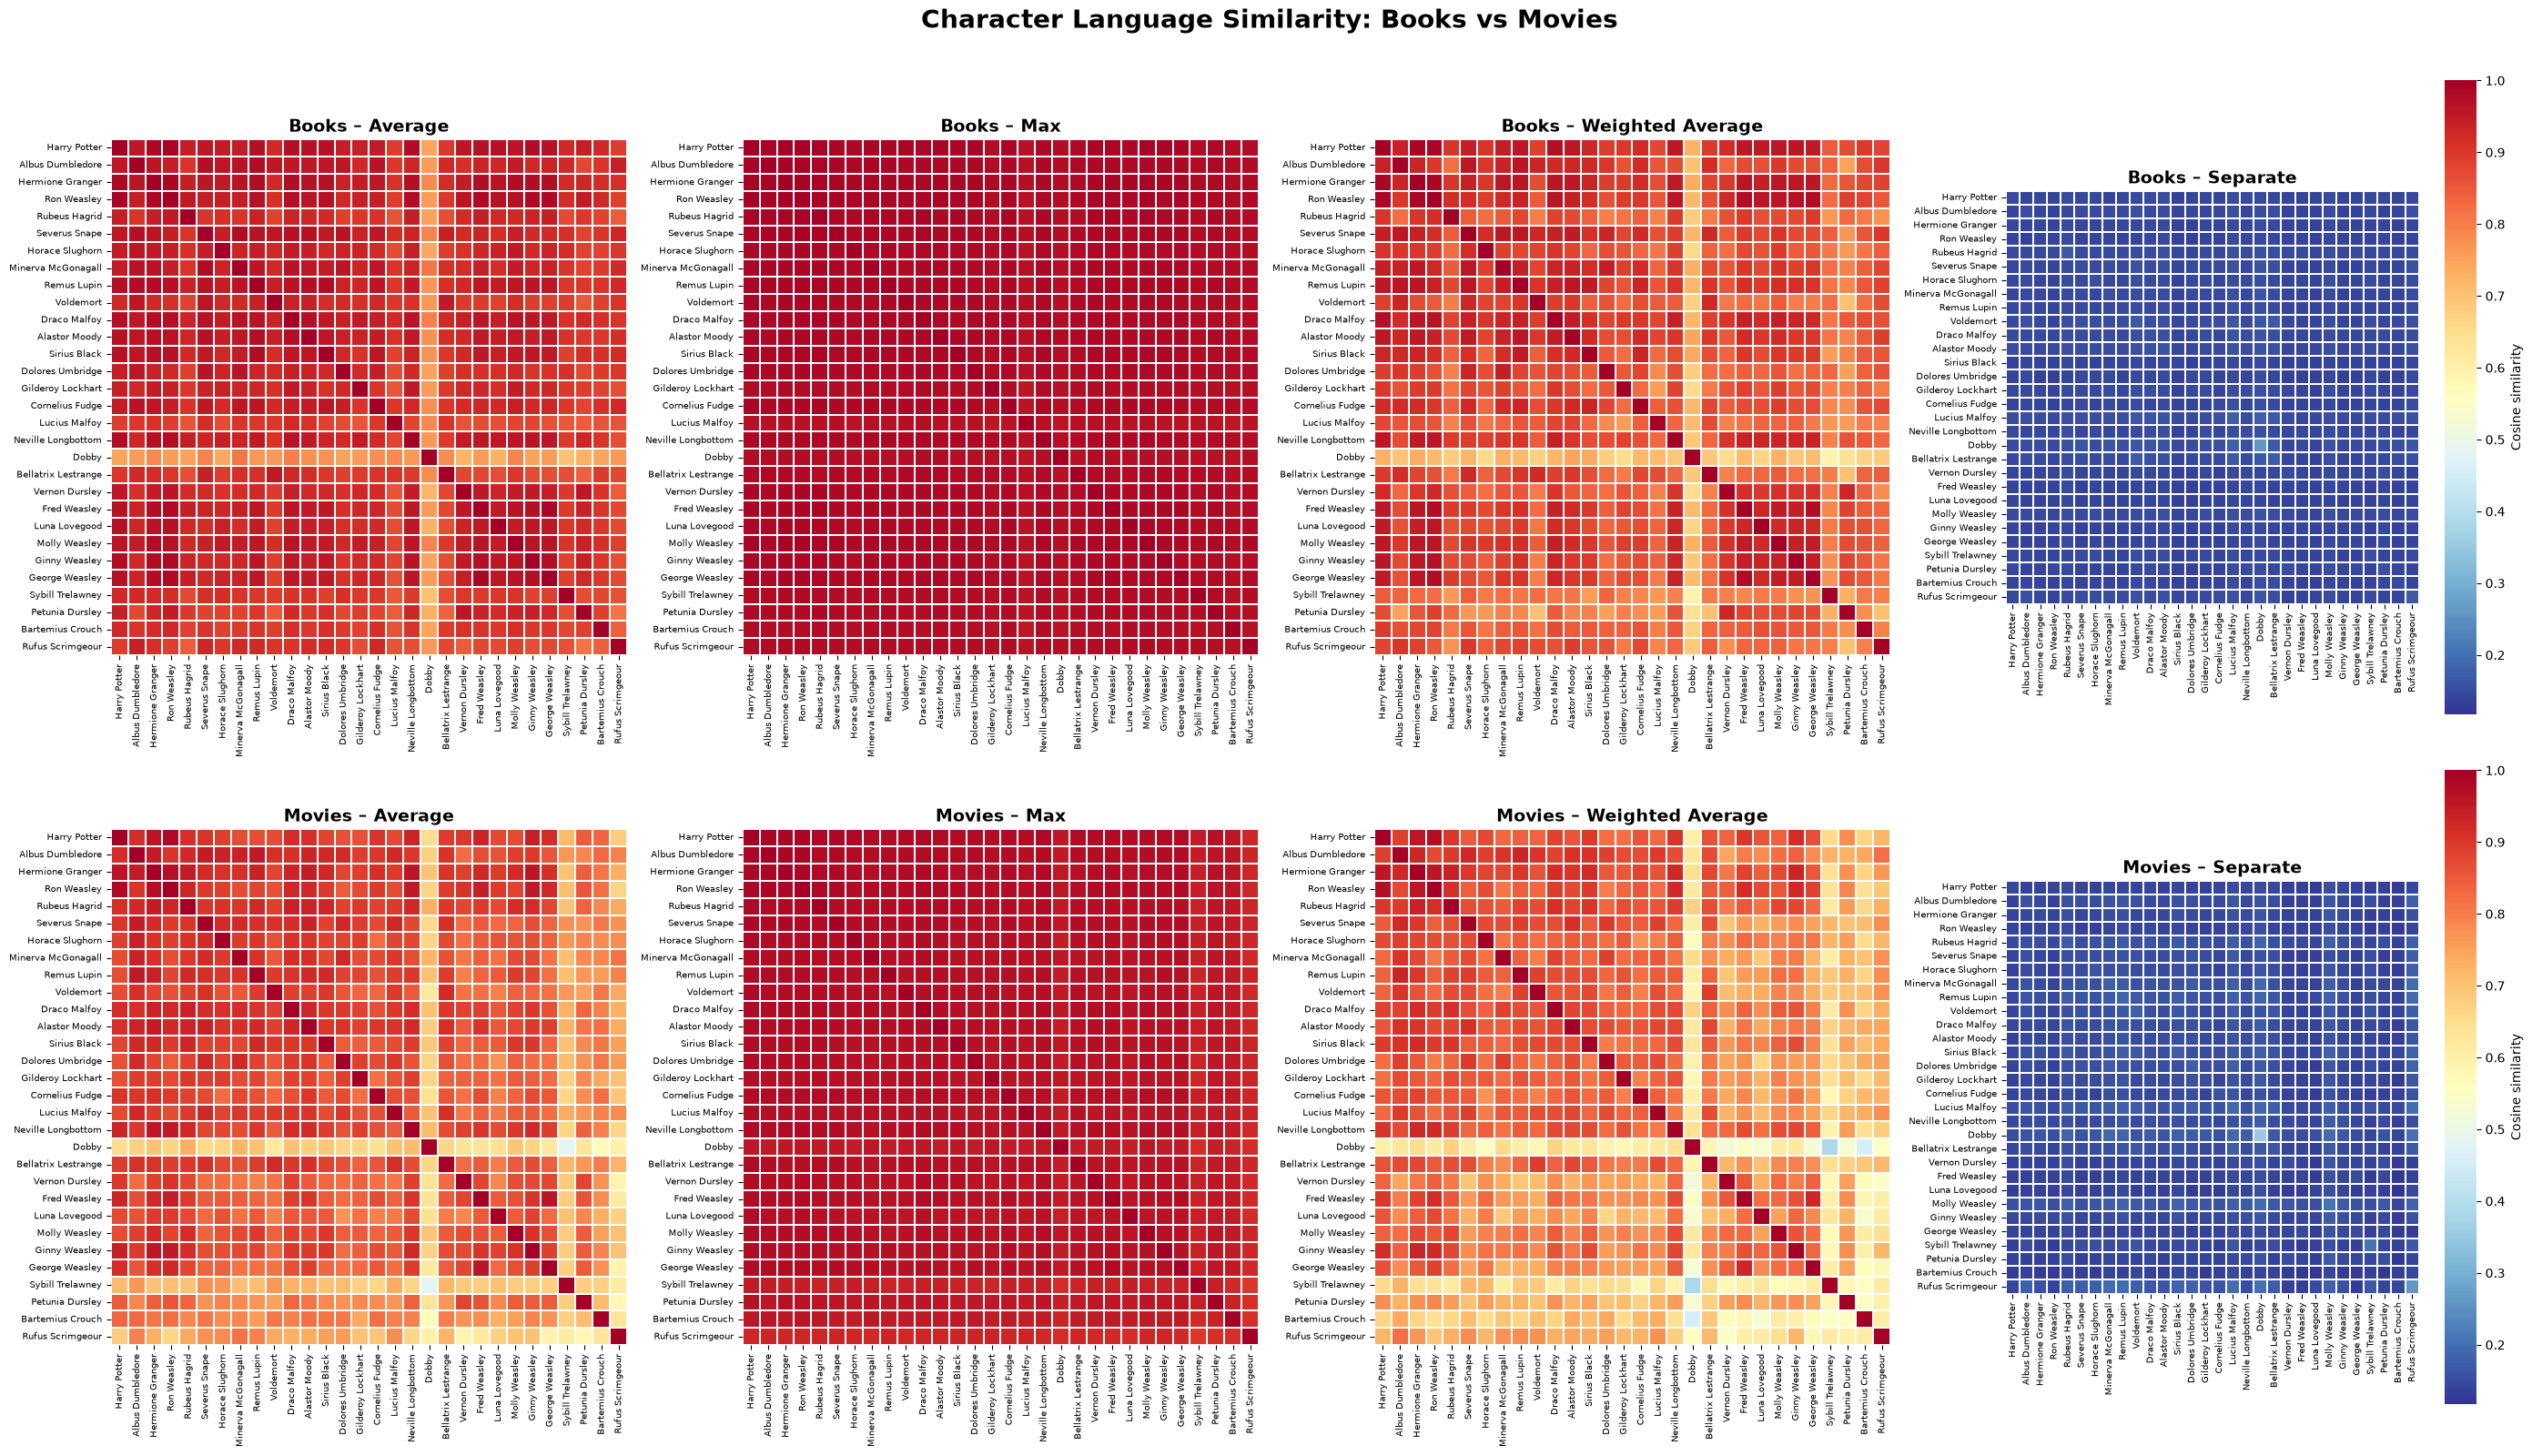

In [110]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

methods = [
    "Average",
    "Max",
    "Weighted Average",
    "Separate"
]

# Use one shared colour scale for all eight matrices
all_values = np.concatenate([
    matrix.to_numpy().flatten()
    for matrices in [book_matrices, movie_matrices]
    for matrix in matrices.values()
])

all_values = all_values[np.isfinite(all_values)]

vmin = all_values.min()
vmax = all_values.max()

fig, axes = plt.subplots(
    2, 4,
    figsize=(28, 16)
)

for col, method in enumerate(methods):

    # BOOKS
    sns.heatmap(
        book_matrices[method],
        ax=axes[0, col],
        cmap="RdYlBu_r",
        vmin=vmin,
        vmax=vmax,
        square=True,
        xticklabels=True,
        yticklabels=True,
        cbar=(col == 3),
        cbar_kws={"label": "Cosine similarity"},
        linewidths=0.1
    )

    axes[0, col].set_title(
        f"Books – {method}",
        fontsize=14,
        fontweight="bold"
    )

    axes[0, col].set_xlabel("")
    axes[0, col].set_ylabel("")

    # MOVIES
    sns.heatmap(
        movie_matrices[method],
        ax=axes[1, col],
        cmap="RdYlBu_r",
        vmin=vmin,
        vmax=vmax,
        square=True,
        xticklabels=True,
        yticklabels=True,
        cbar=(col == 3),
        cbar_kws={"label": "Cosine similarity"},
        linewidths=0.1
    )

    axes[1, col].set_title(
        f"Movies – {method}",
        fontsize=14,
        fontweight="bold"
    )

    axes[1, col].set_xlabel("")
    axes[1, col].set_ylabel("")


# Format character labels
for ax in axes.flat:

    ax.tick_params(
        axis="x",
        labelrotation=90,
        labelsize=7
    )

    ax.tick_params(
        axis="y",
        labelrotation=0,
        labelsize=7
    )

fig.suptitle(
    "Character Language Similarity: Books vs Movies",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


In [111]:

from scipy.stats import spearmanr
from itertools import combinations


def compareSimilarityMatrices(matrices):

    results = []

    for method_a, method_b in combinations(matrices.keys(), 2):

        matrix_a = matrices[method_a].to_numpy()
        matrix_b = matrices[method_b].to_numpy()

        # Only compare unique character pairs
        upper = np.triu_indices_from(matrix_a, k=1)

        values_a = matrix_a[upper]
        values_b = matrix_b[upper]

        # Remove missing values
        valid = np.isfinite(values_a) & np.isfinite(values_b)

        correlation, p_value = spearmanr(
            values_a[valid],
            values_b[valid]
        )

        results.append({
            "Method A": method_a,
            "Method B": method_b,
            "Spearman correlation": correlation,
            "p-value": p_value
        })

    return pd.DataFrame(results)


print("BOOKS")
display(compareSimilarityMatrices(book_matrices))

print("MOVIES")
display(compareSimilarityMatrices(movie_matrices))


BOOKS


,Method A,Method B,Spearman correlation,p-value
0,Average,Max,0.793117,2.781904e-95
1,Average,Weighted Average,0.945973,6.542945e-214
2,Average,Separate,-0.133413,5.319721e-03
3,Max,Weighted Average,0.747502,6.043693e-79
4,Max,Separate,-0.208308,1.185414e-05
5,Weighted Average,Separate,-0.059193,2.179139e-01


MOVIES


,Method A,Method B,Spearman correlation,p-value
0,Average,Max,0.859519,2.712415e-128
1,Average,Weighted Average,0.958241,1.527990e-237
2,Average,Separate,0.177113,2.050221e-04
3,Max,Weighted Average,0.840098,4.275429e-117
4,Max,Separate,-0.021895,6.488190e-01
5,Weighted Average,Separate,0.238521,4.821976e-07


# Character split

# Heatmap character sectioned

In [112]:
# Villains first, ambiguous second, non-villains last
ordered_characters = villains + ambiguous + non_villains

print(ordered_characters)

# Check that all selected characters are included exactly once
assert set(ordered_characters) == set(selected_characters)
assert len(ordered_characters) == len(set(ordered_characters))

# Group sizes
n_villains = len(villains)
n_ambiguous = len(ambiguous)

# Colors for character groups
group_colors = {
    "Villain": "#d73027",
    "Ambiguous": "#fdae61",
    "Non-villain": "#4575b4"
}

character_colors = (
    [group_colors["Villain"]] * len(villains)
    + [group_colors["Ambiguous"]] * len(ambiguous)
    + [group_colors["Non-villain"]] * len(non_villains)
)

['Voldemort', 'Bellatrix Lestrange', 'Dolores Umbridge', 'Lucius Malfoy', 'Severus Snape', 'Draco Malfoy', 'Horace Slughorn', 'Gilderoy Lockhart', 'Cornelius Fudge', 'Vernon Dursley', 'Petunia Dursley', 'Bartemius Crouch', 'Rufus Scrimgeour', 'Harry Potter', 'Albus Dumbledore', 'Hermione Granger', 'Ron Weasley', 'Rubeus Hagrid', 'Minerva McGonagall', 'Remus Lupin', 'Alastor Moody', 'Sirius Black', 'Neville Longbottom', 'Dobby', 'Fred Weasley', 'Luna Lovegood', 'Molly Weasley', 'Ginny Weasley', 'George Weasley', 'Sybill Trelawney']


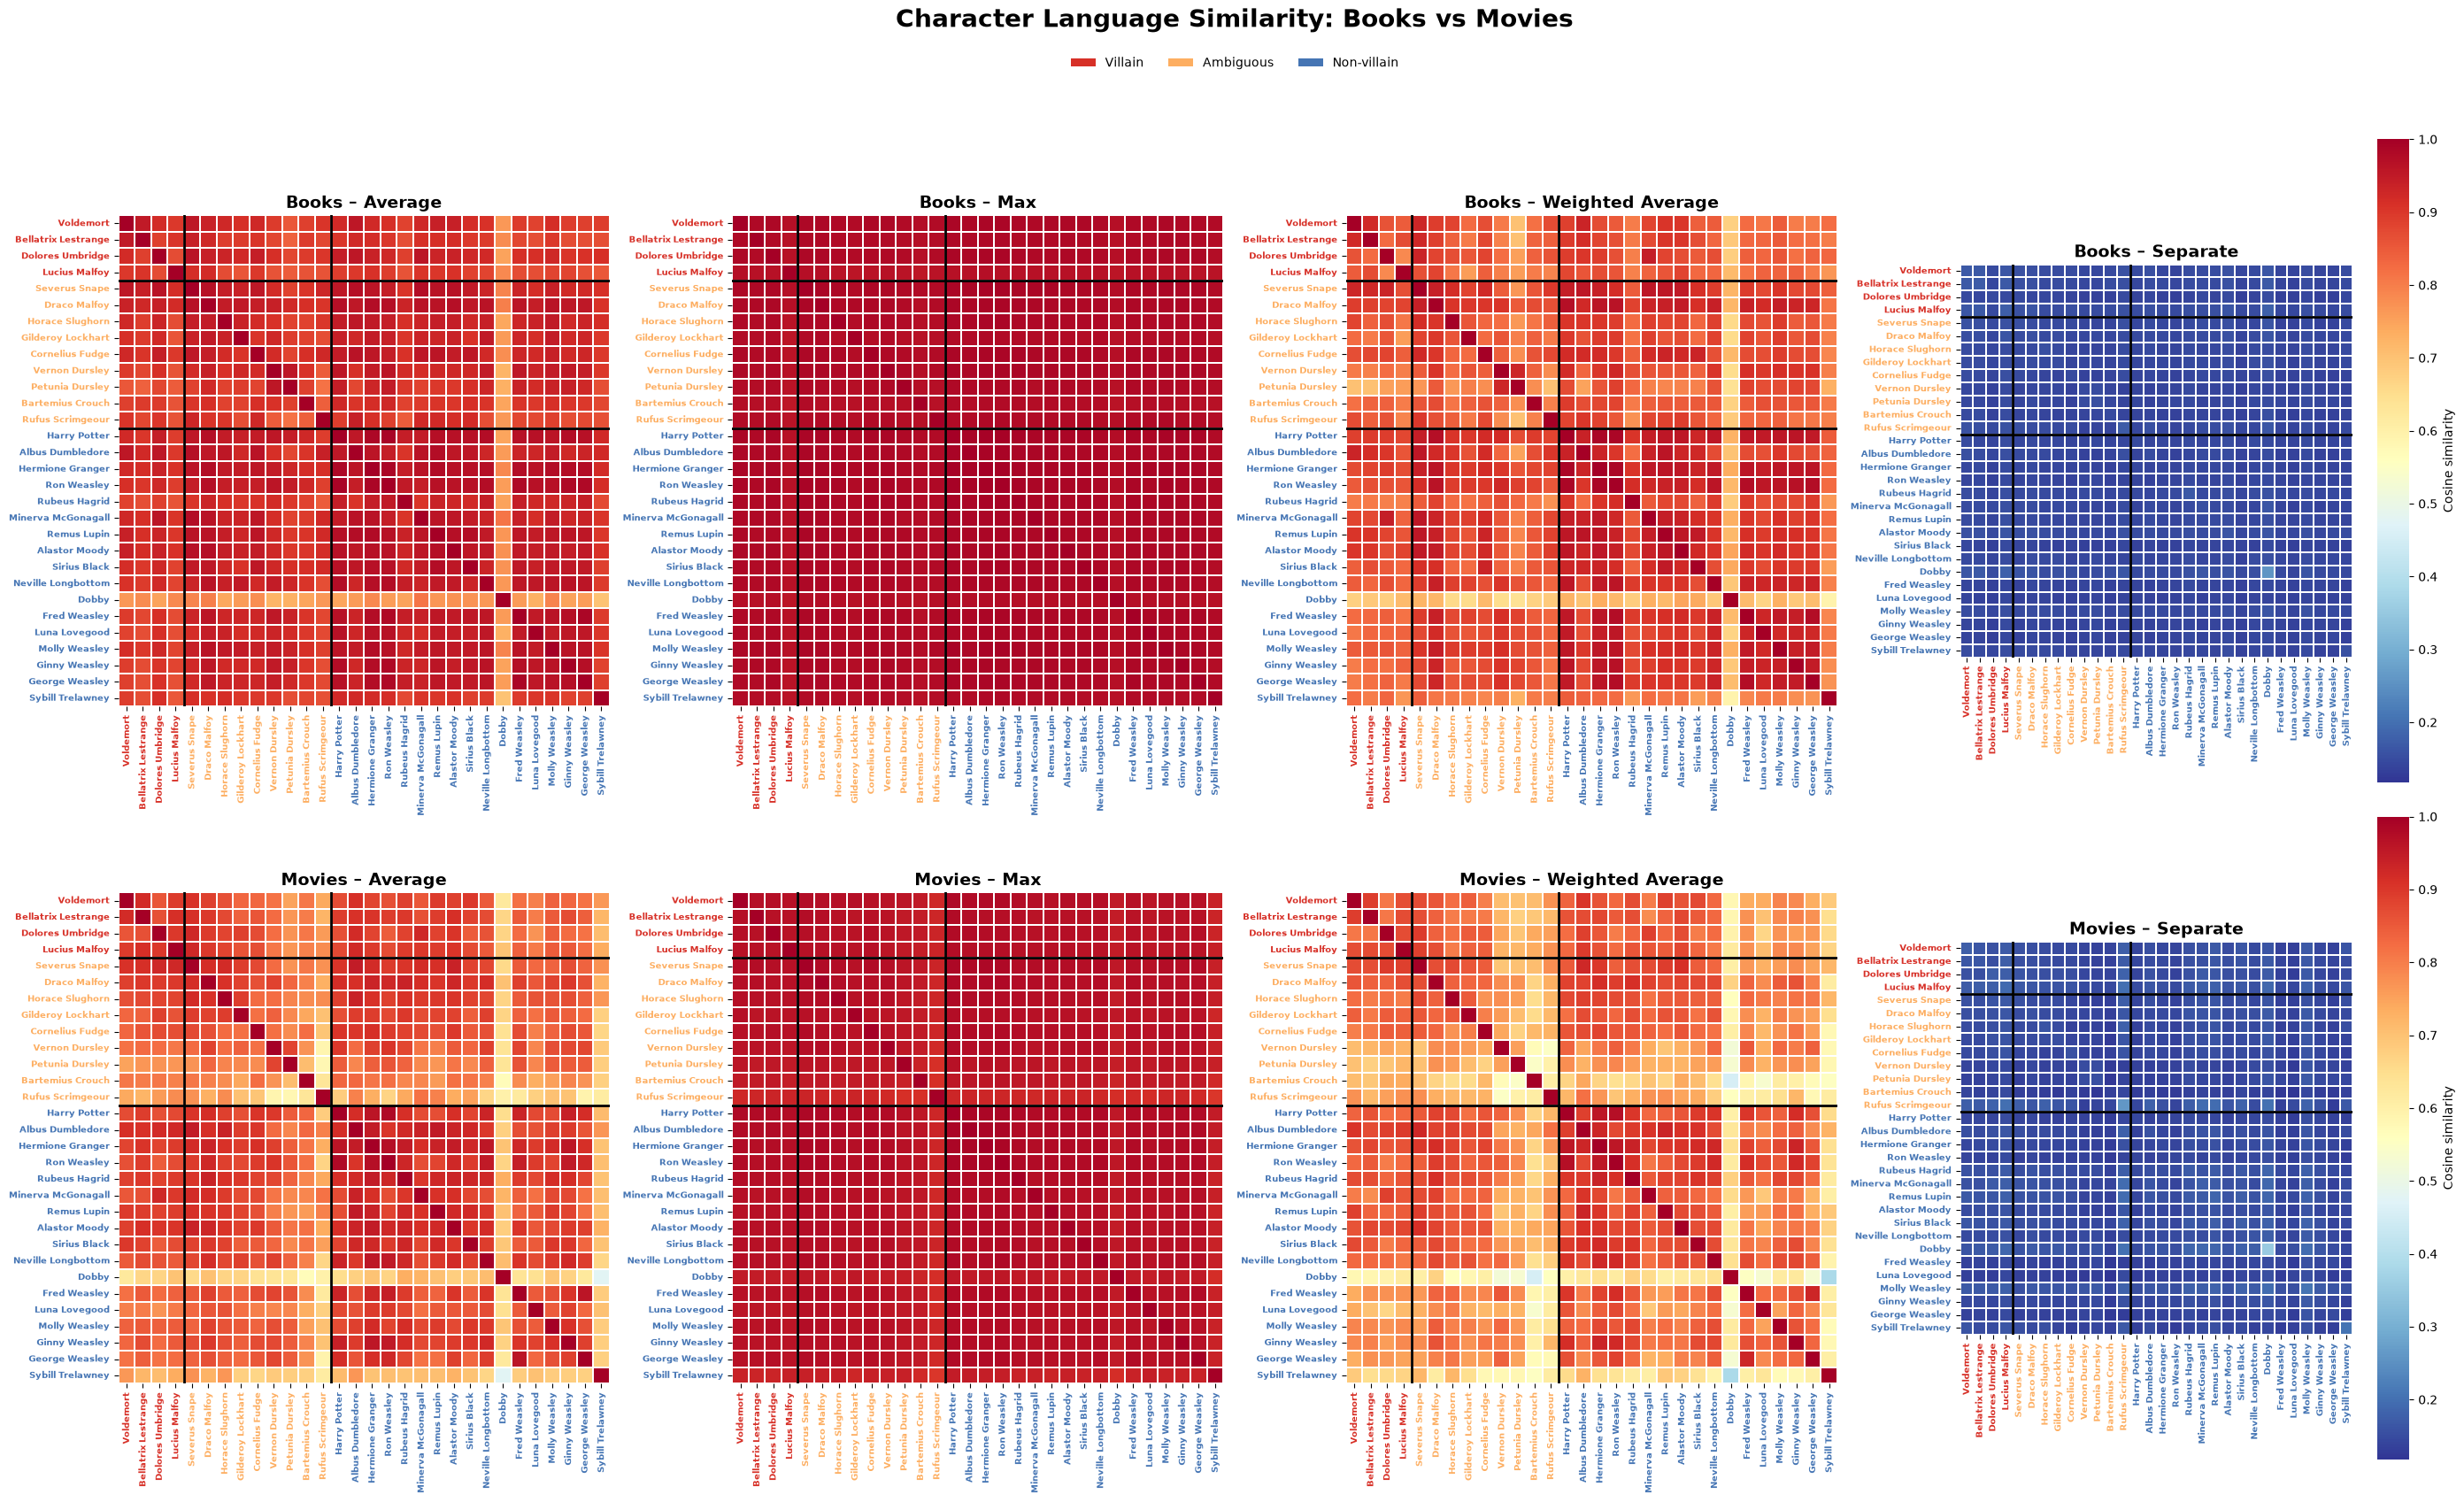

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

methods = [
    "Average",
    "Max",
    "Weighted Average",
    "Separate"
]

# Use one shared colour scale for all eight matrices
all_values = np.concatenate([
    matrix.loc[ordered_characters, ordered_characters]
          .to_numpy()
          .flatten()
    for matrices in [book_matrices, movie_matrices]
    for matrix in matrices.values()
])

all_values = all_values[np.isfinite(all_values)]

vmin = all_values.min()
vmax = all_values.max()

# Create figure
fig, axes = plt.subplots(
    2, 4,
    figsize=(28, 17)
)

for col, method in enumerate(methods):

    for row, matrices in enumerate([book_matrices, movie_matrices]):

        ax = axes[row, col]

        # Reorder rows and columns into the three character groups
        similarity_df = matrices[method].loc[
            ordered_characters,
            ordered_characters
        ]

        sns.heatmap(
            similarity_df,
            ax=ax,
            cmap="RdYlBu_r",
            vmin=vmin,
            vmax=vmax,
            square=True,
            xticklabels=True,
            yticklabels=True,
            cbar=(col == 3),
            cbar_kws={"label": "Cosine similarity"},
            linewidths=0.1
        )

        # Titles
        version = "Books" if row == 0 else "Movies"

        ax.set_title(
            f"{version} – {method}",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel("")
        ax.set_ylabel("")

        # Format tick labels
        ax.tick_params(
            axis="x",
            labelrotation=90,
            labelsize=7
        )

        ax.tick_params(
            axis="y",
            labelrotation=0,
            labelsize=7
        )

        # Color character labels according to their group
        for i, label in enumerate(ax.get_xticklabels()):
            label.set_color(character_colors[i])
            label.set_fontweight("bold")

        for i, label in enumerate(ax.get_yticklabels()):
            label.set_color(character_colors[i])
            label.set_fontweight("bold")

        # Add separator lines between character groups
        boundaries = [
            n_villains,
            n_villains + n_ambiguous
        ]

        for boundary in boundaries:
            ax.axhline(boundary, color="black", linewidth=2)
            ax.axvline(boundary, color="black", linewidth=2)


# Main title
fig.suptitle(
    "Character Language Similarity: Books vs Movies",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

# Shared legend
legend_elements = [
    Patch(facecolor=group_colors["Villain"], label="Villain"),
    Patch(facecolor=group_colors["Ambiguous"], label="Ambiguous"),
    Patch(facecolor=group_colors["Non-villain"], label="Non-villain")
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=3,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()